# ARTI403: Image Processing
## Lab 5: Spatial Filtering, Smoothing and Sharpening

**Student Name:** Saad Abdulaziz Alshehri  
**Student ID:** 2240006495


In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

os.makedirs('images', exist_ok=True)
%matplotlib inline

# Save the sample images used in this lab (the Parrot image from the manual is not available)
cv2.imwrite('images/chelsea.png', cv2.cvtColor(data.chelsea(), cv2.COLOR_RGB2BGR))
cv2.imwrite('images/astronaut.png', cv2.cvtColor(data.astronaut(), cv2.COLOR_RGB2BGR))

True

# Section 3: Procedural Steps
## Task 1: Unsharp Masking

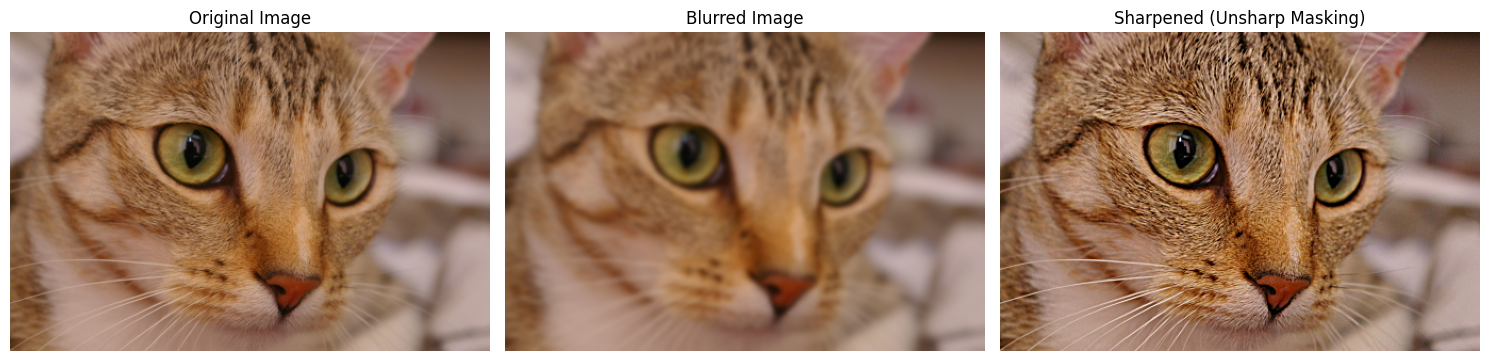

In [2]:
# Read the image
image = cv2.imread('images/chelsea.png')
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Convert from BGR to RGB

# Gaussian sigma
sigma = 2
# Parameter
amount = 1.5

# Convert image to float32 for processing
image_float = image.astype(np.float32) / 255.0

# Apply Gaussian blur
blurred = cv2.GaussianBlur(image_float, (0, 0), sigmaX=sigma, sigmaY=sigma)

# Perform Unsharp Masking
sharpened = np.clip(image_float + amount * (image_float - blurred), 0, 1)

# Plot original, blurred, and sharpened images
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(image)
ax[0].set_title("Original Image")
ax[0].axis("off")
ax[1].imshow(blurred)
ax[1].set_title("Blurred Image")
ax[1].axis("off")
ax[2].imshow(sharpened)
ax[2].set_title("Sharpened (Unsharp Masking)")
ax[2].axis("off")
plt.tight_layout()
plt.savefig('images/task1_unsharp_masking.png', dpi=120, bbox_inches='tight')
plt.show()

# Section 4: Assessment
## Task 1: Convolve an image with a 7x7 box filter

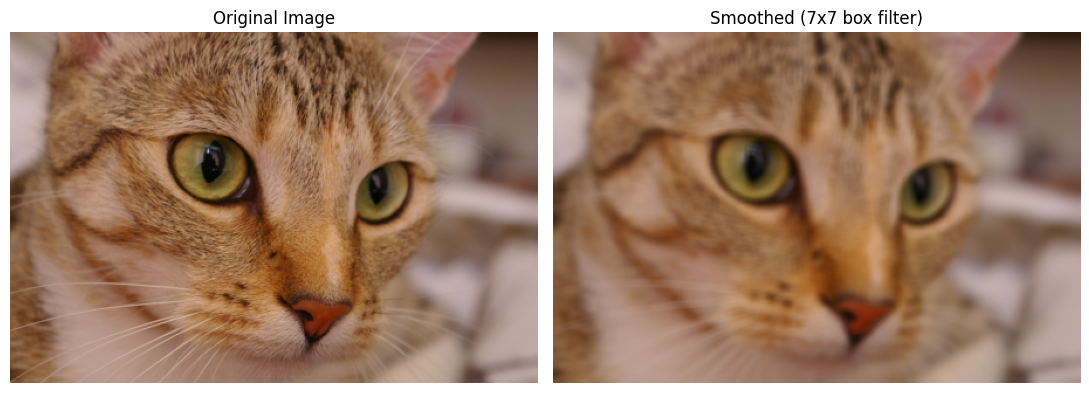

In [3]:
image = cv2.cvtColor(cv2.imread('images/chelsea.png'), cv2.COLOR_BGR2RGB)

# 7x7 box filter: every value is 1/49, so the output is the local average
box_kernel = np.ones((7, 7), np.float32) / (7 * 7)
smoothed = cv2.filter2D(image, -1, box_kernel)

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(image)
ax[0].set_title('Original Image')
ax[0].axis('off')
ax[1].imshow(smoothed)
ax[1].set_title('Smoothed (7x7 box filter)')
ax[1].axis('off')
plt.tight_layout()
plt.savefig('images/assessment1_box_filter.png', dpi=120, bbox_inches='tight')
plt.show()

## Task 2: 5x5 and 21x21 Gaussian filters (astronaut image)

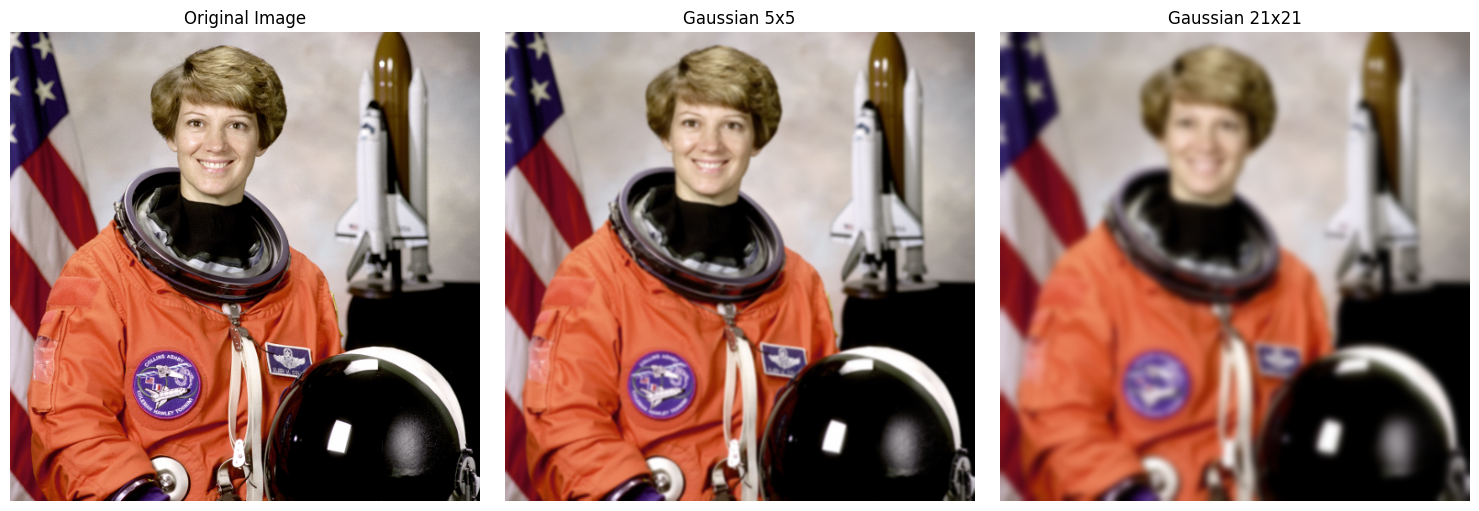

In [4]:
image = cv2.cvtColor(cv2.imread('images/astronaut.png'), cv2.COLOR_BGR2RGB)

# sigma = 0 lets OpenCV compute sigma from the kernel size
gauss_5 = cv2.GaussianBlur(image, (5, 5), 0)
gauss_21 = cv2.GaussianBlur(image, (21, 21), 0)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, im, t in zip(ax, [image, gauss_5, gauss_21],
                    ['Original Image', 'Gaussian 5x5', 'Gaussian 21x21']):
    a.imshow(im)
    a.set_title(t)
    a.axis('off')
plt.tight_layout()
plt.savefig('images/assessment2_gaussian.png', dpi=120, bbox_inches='tight')
plt.show()

## Task 3: Sharpening with a 3x3 Laplacian filter (astronaut image)

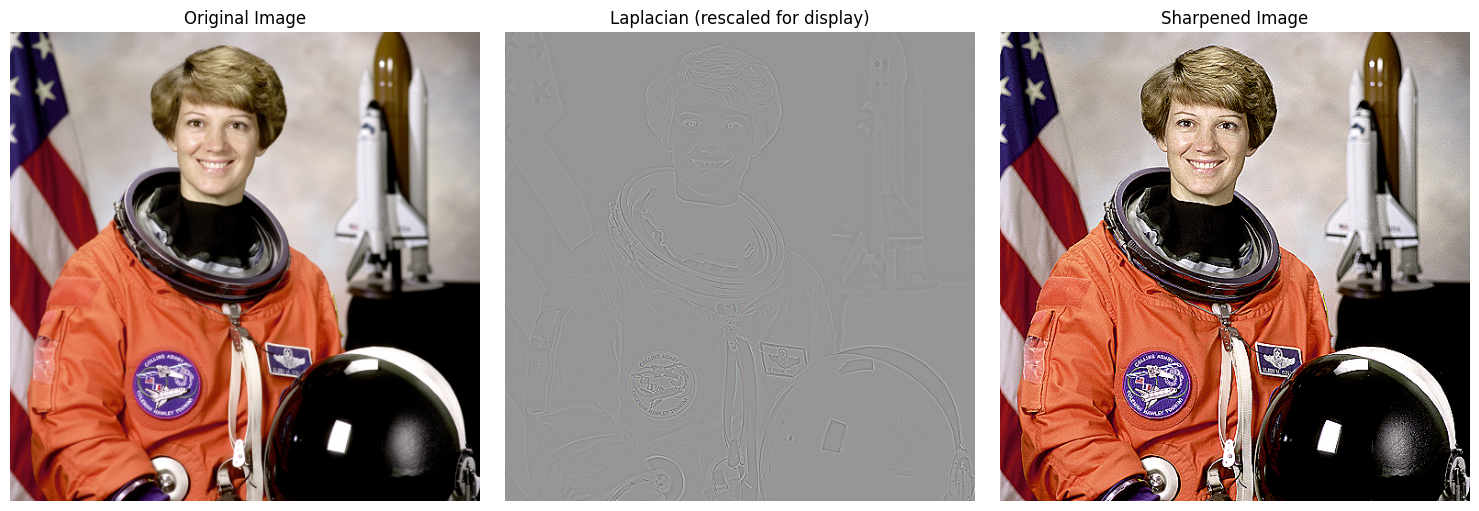

In [5]:
# Read the image
image = cv2.cvtColor(cv2.imread('images/astronaut.png'), cv2.COLOR_BGR2RGB)

# Convert image to float32
image_float = image.astype(np.float32) / 255.0

# 3x3 Laplacian (ksize=1 uses the kernel [[0, 1, 0], [1, -4, 1], [0, 1, 0]])
laplacian = cv2.Laplacian(image_float, cv2.CV_32F, ksize=1)

# Sharpen the image
sharpened = np.clip(image_float - laplacian, 0, 1)

# The Laplacian has negative values, so it is rescaled to 0-1 only for display
laplacian_display = (laplacian - laplacian.min()) / (laplacian.max() - laplacian.min())

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, im, t in zip(ax, [image, laplacian_display, sharpened],
                    ['Original Image', 'Laplacian (rescaled for display)', 'Sharpened Image']):
    a.imshow(im)
    a.set_title(t)
    a.axis('off')
plt.tight_layout()
plt.savefig('images/assessment3_laplacian.png', dpi=120, bbox_inches='tight')
plt.show()